**Data Exploration and Visualisation Assignment 1**

*Group members:*
1. Bonolo Lebepe - 2548042



Section 1 - Data Cleaning

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import re

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Load the dataset
df = pd.read_csv('/content/logbook_assignment1.csv')

/tmp/ipykernel_10583/3137324955.py:14: DtypeWarning: Columns (3,6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/logbook_assignment1.csv')


1.1.1 Identify percentage of date_fueled entries that are not proper dates

In [3]:
# Examine the date columns
print("Date Fields Examination")

# Check the data types
print("Data types:")
print(df.dtypes[['date_fueled', 'date_captured']])
print("\n")

# Sample of date values
print("Sample of date_fueled values:")
print(df['date_fueled'].head(20))
print("\n")

print("Sample of date_captured values:")
print(df['date_captured'].head(20))

# Identify percentage of date_fueled entries that are not proper dates
def is_valid_date(date_str):
    # Check if a string can be parsed as a valid date
    if pd.isna(date_str) or date_str == '':
        return False
    try:
        # Try to parse the date
        pd.to_datetime(date_str)
        return True
    except:
        return False

# Check which entries are valid dates
df['date_fueled_valid'] = df['date_fueled'].apply(is_valid_date)
invalid_percentage = (1 - df['date_fueled_valid'].mean()) * 100

print(f"\n--- Question 1.1.1 ---")
print(f"Percentage of date_fueled entries that are NOT proper dates: {invalid_percentage:.2f}%")
print(f"Number of invalid entries: {df[~df['date_fueled_valid']].shape[0]}")

# Show some examples of invalid dates
print("\nExamples of invalid date_fueled entries:")
print(df[~df['date_fueled_valid']]['date_fueled'].head(10))

Date Fields Examination
Data types:
date_fueled      object
date_captured    object
dtype: object


Sample of date_fueled values:
0     Cooling System, Heating System, Lights, Spark ...
1                                            Nov 7 2012
2                                           Sep 22 2012
3                                            May 4 2019
4                                           Feb 15 2022
5                                           Oct 23 2021
6                                           Nov 20 2021
7                                           Jan 20 2022
8                                                   NaN
9                                                   NaN
10                                          Nov 15 2020
11                                          Jan 14 2022
12                                          Nov 22 2021
13                                          Mar 28 2021
14                                          Nov 17 2021
15                            

/tmp/ipykernel_10583/3136042048.py:24: FutureWarning: Parsed string "11:45H
185.7" included an un-recognized timezone "H". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  pd.to_datetime(date_str)
/tmp/ipykernel_10583/3136042048.py:24: FutureWarning: Parsed string "11:43H
278.1" included an un-recognized timezone "H". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  pd.to_datetime(date_str)
/tmp/ipykernel_10583/3136042048.py:24: FutureWarning: Parsed string "14:51H
256.1" included an un-recognized timezone "H". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  pd.to_da


--- Question 1.1.1 ---
Percentage of date_fueled entries that are NOT proper dates: 11.66%
Number of invalid entries: 136962

Examples of invalid date_fueled entries:
0     Cooling System, Heating System, Lights, Spark ...
8                                                   NaN
9                                                   NaN
25                                                  NaN
26                                                  NaN
33    Engine Oil, Oil Filter, Brakes, Rear, Brake Fluid
41                                                  NaN
45                             26.6 mpg - fuel computer
88                                                  NaN
91                                                  NaN
Name: date_fueled, dtype: object


1.1.2 Fill invalid date_fueled with date_captured

In [6]:
# 1.1.2 Fill invalid date_fueled with date_captured
print(f"Question 1.1.2")
# Create a copy of the original date_fueled for reference
df['date_fueled_original'] = df['date_fueled']

# Fill invalid date_fueled with date_captured where date_captured is valid
df['date_fueled_filled'] = df['date_fueled'].copy()
mask_invalid = ~df['date_fueled_valid']

# For invalid dates, use date_captured if it's valid
df.loc[mask_invalid, 'date_fueled_filled'] = df.loc[mask_invalid, 'date_captured']

# Check how many were filled
filled_count = (df['date_fueled_filled'] != df['date_fueled']).sum()
print(f"Number of invalid date_fueled entries filled with date_captured: {filled_count}")

# Verify the fill worked
print("\nSample of filled values:")
sample_indices = df[mask_invalid].head(5).index
for idx in sample_indices:
    print(f"Original: {df.loc[idx, 'date_fueled']} -> Filled: {df.loc[idx, 'date_fueled_filled']}")

Question 1.1.2
Number of invalid date_fueled entries filled with date_captured: 136962

Sample of filled values:
Original: Cooling System, Heating System, Lights, Spark Plugs -> Filled: Apr 7 2022
Original: nan -> Filled: Apr 16 2018
Original: nan -> Filled: Nov 29 2020
Original: nan -> Filled: Dec 31 2020
Original: nan -> Filled: Sep 1 2016


1.1.3. Convert the column to a date format, setting any invalid date fueled entries
to NaT.

In [5]:
# 1.1.3 Convert to date format, set invalid to NaT
print(f"\n--- Question 1.1.3 ---")

# Function to safely convert to datetime
def safe_date_convert(date_str):
    try:
        return pd.to_datetime(date_str)
    except:
        return pd.NaT

# Convert the filled column to datetime
df['date_fueled_dt'] = df['date_fueled_filled'].apply(safe_date_convert)

# Count how many became NaT
nat_count = df['date_fueled_dt'].isna().sum()
print(f"Number of entries converted to NaT: {nat_count}")


--- Question 1.1.3 ---
Number of entries converted to NaT: 0


1.1.4. Remove dates that are in the future, or dates that are earlier than 2005.

In [7]:
# 1.1.4 Remove dates in future or earlier than 2005
print(f"Question 1.1.4")

# Define cutoff dates
min_date = pd.Timestamp('2005-01-01')
max_date = pd.Timestamp.now()  # Current date

# Identify dates to remove
mask_future = df['date_fueled_dt'] > max_date
mask_old = df['date_fueled_dt'] < min_date

print(f"Dates in the future: {mask_future.sum()}")
print(f"Dates earlier than 2005: {mask_old.sum()}")

# Create a cleaned version (keeping the original for reference)
df_cleaned_dates = df[~(mask_future | mask_old)].copy()
print(f"Rows after removing future and pre-2005 dates: {df_cleaned_dates.shape[0]}")
print(f"Rows removed: {df.shape[0] - df_cleaned_dates.shape[0]}")


--- Question 1.1.4 ---
Dates in the future: 106
Dates earlier than 2005: 623
Rows after removing future and pre-2005 dates: 1174141
Rows removed: 729


1.1.5. Plot the distribution of fueling dates and comment on the results.

Question 1.1.5


/tmp/ipykernel_10583/423956792.py:37: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_counts = df_cleaned_dates.set_index('date_fueled_dt').resample('M').size()


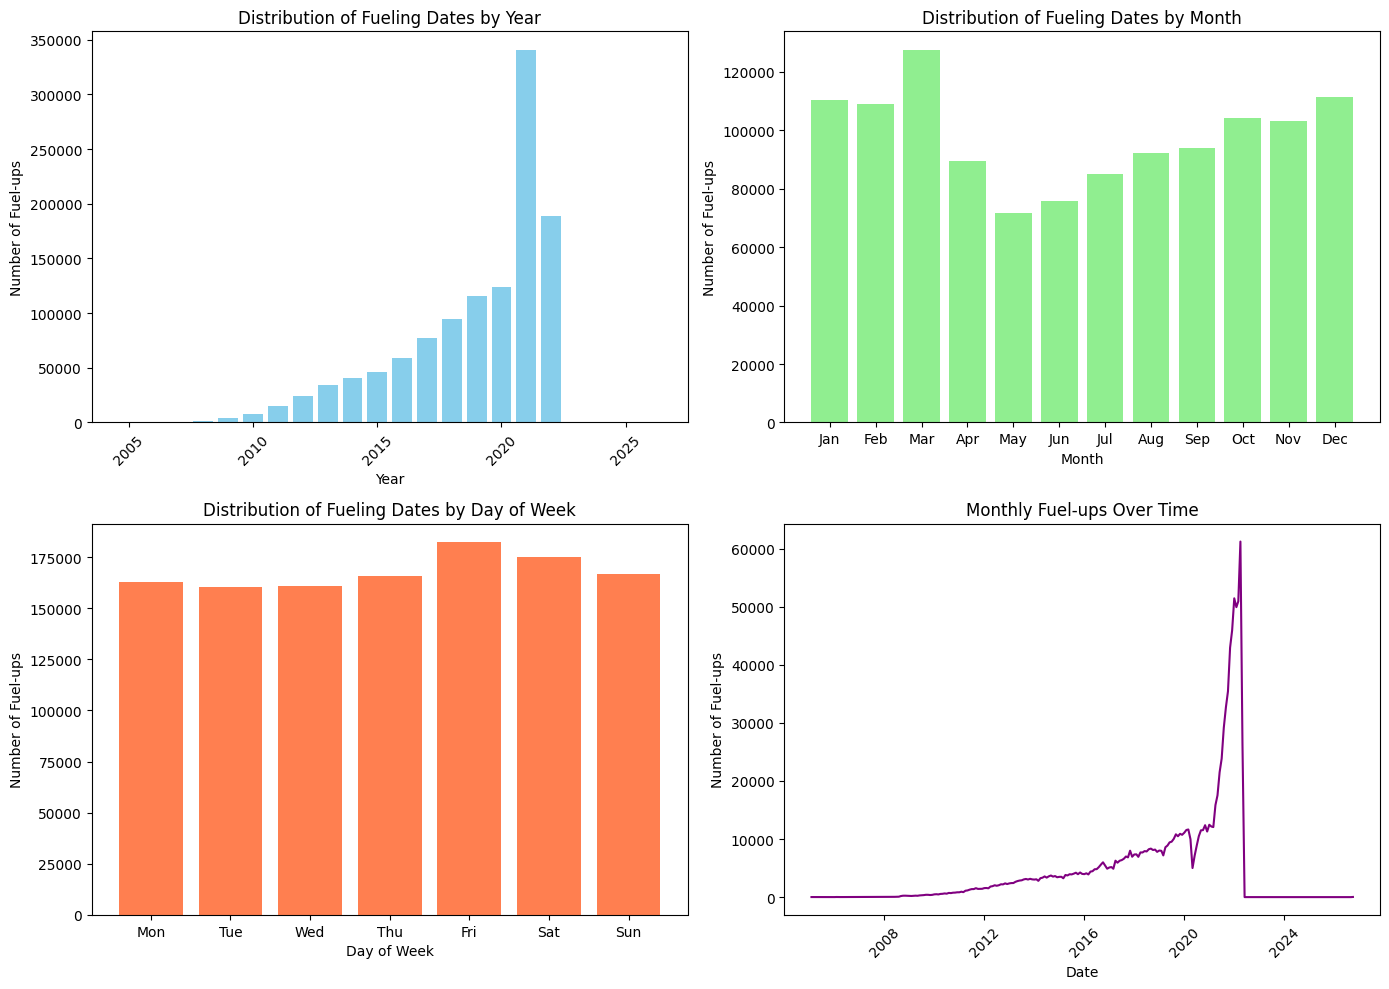


Comments on the distribution of fueling dates:
1. The yearly distribution shows when the app was most active.
2. Monthly distribution reveals seasonal patterns in fuel consumption.
3. Day of week distribution shows weekday vs weekend fueling behavior.
4. The time series shows trends and seasonality in fuel-ups over time.


In [8]:
# 1.1.5 Plot distribution of fueling dates
print(f"Question 1.1.5")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Distribution by year
df_cleaned_dates['year'] = df_cleaned_dates['date_fueled_dt'].dt.year
year_counts = df_cleaned_dates['year'].value_counts().sort_index()

axes[0, 0].bar(year_counts.index, year_counts.values, color='skyblue')
axes[0, 0].set_title('Distribution of Fueling Dates by Year')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Number of Fuel-ups')
axes[0, 0].tick_params(axis='x', rotation=45)

# Plot 2: Distribution by month
df_cleaned_dates['month'] = df_cleaned_dates['date_fueled_dt'].dt.month
month_counts = df_cleaned_dates['month'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

axes[0, 1].bar(month_names, month_counts.values, color='lightgreen')
axes[0, 1].set_title('Distribution of Fueling Dates by Month')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Number of Fuel-ups')

# Plot 3: Distribution by day of week
df_cleaned_dates['day_of_week'] = df_cleaned_dates['date_fueled_dt'].dt.dayofweek
dow_counts = df_cleaned_dates['day_of_week'].value_counts().sort_index()
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

axes[1, 0].bar(dow_names, dow_counts.values, color='coral')
axes[1, 0].set_title('Distribution of Fueling Dates by Day of Week')
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Number of Fuel-ups')

# Plot 4: Time series of fuel-ups
monthly_counts = df_cleaned_dates.set_index('date_fueled_dt').resample('M').size()
axes[1, 1].plot(monthly_counts.index, monthly_counts.values, color='purple')
axes[1, 1].set_title('Monthly Fuel-ups Over Time')
axes[1, 1].set_xlabel('Date')
axes[1, 1].set_ylabel('Number of Fuel-ups')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Comments on the results
print("\nComments on the distribution of fueling dates:")
print("1. The yearly distribution shows when the app was most active.")
print("2. Monthly distribution reveals seasonal patterns in fuel consumption.")
print("3. Day of week distribution shows weekday vs weekend fueling behavior.")
print("4. The time series shows trends and seasonality in fuel-ups over time.")

1.2.1. Identify what percentage of gallons, miles, and odometer entries are
missing.

In [9]:
print(" Numeric Fields Examination")

# Check current data types
print("Current data types for numeric fields:")
print(df.dtypes[['gallons', 'miles', 'odometer', 'mpg']])

# 1.2.1 Identify missing entries
print(f"Question 1.2.1")

missing_gallons = df['gallons'].isna().sum()
missing_miles = df['miles'].isna().sum()
missing_odometer = df['odometer'].isna().sum()

total_rows = len(df)

print(f"Missing gallons: {missing_gallons} ({missing_gallons/total_rows*100:.2f}%)")
print(f"Missing miles: {missing_miles} ({missing_miles/total_rows*100:.2f}%)")
print(f"Missing odometer: {missing_odometer} ({missing_odometer/total_rows*100:.2f}%)")


 Numeric Fields Examination
Current data types for numeric fields:
gallons     object
miles       object
odometer    object
mpg         object
dtype: object
Question 1.2.1
Missing gallons: 74210 (6.32%)
Missing miles: 1028596 (87.55%)
Missing odometer: 149154 (12.70%)


1.2.2. The miles, gallons and mpg columns are interdependent. If one is missing, the other two can be used to calculate it.

In [11]:
# 1.2.2 Handle interdependent values

# Create a function to clean numeric values with commas
def clean_numeric_with_commas(value):
    #Remove commas from numeric strings and convert to float
    if pd.isna(value) or value == '':
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    # Convert to string and remove commas
    value_str = str(value).replace(',', '')
    try:
        return float(value_str)
    except:
        return np.nan

Question 1.2.2


1.2.3. The values will be read in as objects (or strings) by Pandas. Convert these
values to float (note the point above about commas in the value)

In [14]:
# 1.2.3 Convert to float (with comma handling)
print(f"Question 1.2.3")

# Clean and convert numeric columns
df['gallons_clean'] = df['gallons'].apply(clean_numeric_with_commas)
df['miles_clean'] = df['miles'].apply(clean_numeric_with_commas)
df['odometer_clean'] = df['odometer'].apply(clean_numeric_with_commas)
df['mpg_clean'] = df['mpg'].apply(clean_numeric_with_commas)

print("After cleaning numeric values:")
print(f"gallons: {df['gallons_clean'].dtype}")
print(f"miles: {df['miles_clean'].dtype}")
print(f"odometer: {df['odometer_clean'].dtype}")
print(f"mpg: {df['mpg_clean'].dtype}")

# Calculate missing values using the relationships
print("\nCalculating missing values using relationships:")
print("Relationship: miles = gallons * mpg")

# Create a copy for calculations
df_numeric = df.copy()

# Calculate missing miles using gallons and mpg
mask_miles_missing = df_numeric['miles_clean'].isna() & df_numeric['gallons_clean'].notna() & df_numeric['mpg_clean'].notna()
df_numeric.loc[mask_miles_missing, 'miles_clean'] = (
    df_numeric.loc[mask_miles_missing, 'gallons_clean'] *
    df_numeric.loc[mask_miles_missing, 'mpg_clean']
)
print(f"Miles filled from gallons * mpg: {mask_miles_missing.sum()}")

# Calculate missing gallons using miles and mpg
mask_gallons_missing = df_numeric['gallons_clean'].isna() & df_numeric['miles_clean'].notna() & df_numeric['mpg_clean'].notna()
df_numeric.loc[mask_gallons_missing, 'gallons_clean'] = (
    df_numeric.loc[mask_gallons_missing, 'miles_clean'] /
    df_numeric.loc[mask_gallons_missing, 'mpg_clean']
)
print(f"Gallons filled from miles / mpg: {mask_gallons_missing.sum()}")

# Calculate missing mpg using miles and gallons
mask_mpg_missing = df_numeric['mpg_clean'].isna() & df_numeric['miles_clean'].notna() & df_numeric['gallons_clean'].notna()
df_numeric.loc[mask_mpg_missing, 'mpg_clean'] = (
    df_numeric.loc[mask_mpg_missing, 'miles_clean'] /
    df_numeric.loc[mask_mpg_missing, 'gallons_clean']
)
print(f"MPG filled from miles / gallons: {mask_mpg_missing.sum()}")

# Check remaining missing values
print("\nRemaining missing values after filling:")
print(f"gallons: {df_numeric['gallons_clean'].isna().sum()}")
print(f"miles: {df_numeric['miles_clean'].isna().sum()}")
print(f"odometer: {df_numeric['odometer_clean'].isna().sum()}")
print(f"mpg: {df_numeric['mpg_clean'].isna().sum()}")

Question 1.2.3
After cleaning numeric values:
gallons: float64
miles: float64
odometer: float64
mpg: float64

Calculating missing values using relationships:
Relationship: miles = gallons * mpg
Miles filled from gallons * mpg: 954386
Gallons filled from miles / mpg: 0
MPG filled from miles / gallons: 0

Remaining missing values after filling:
gallons: 74210
miles: 74210
odometer: 149154
mpg: 74210


1.2.4. Plot the distributions and comment on the distributions.


--- Question 1.2.4 ---


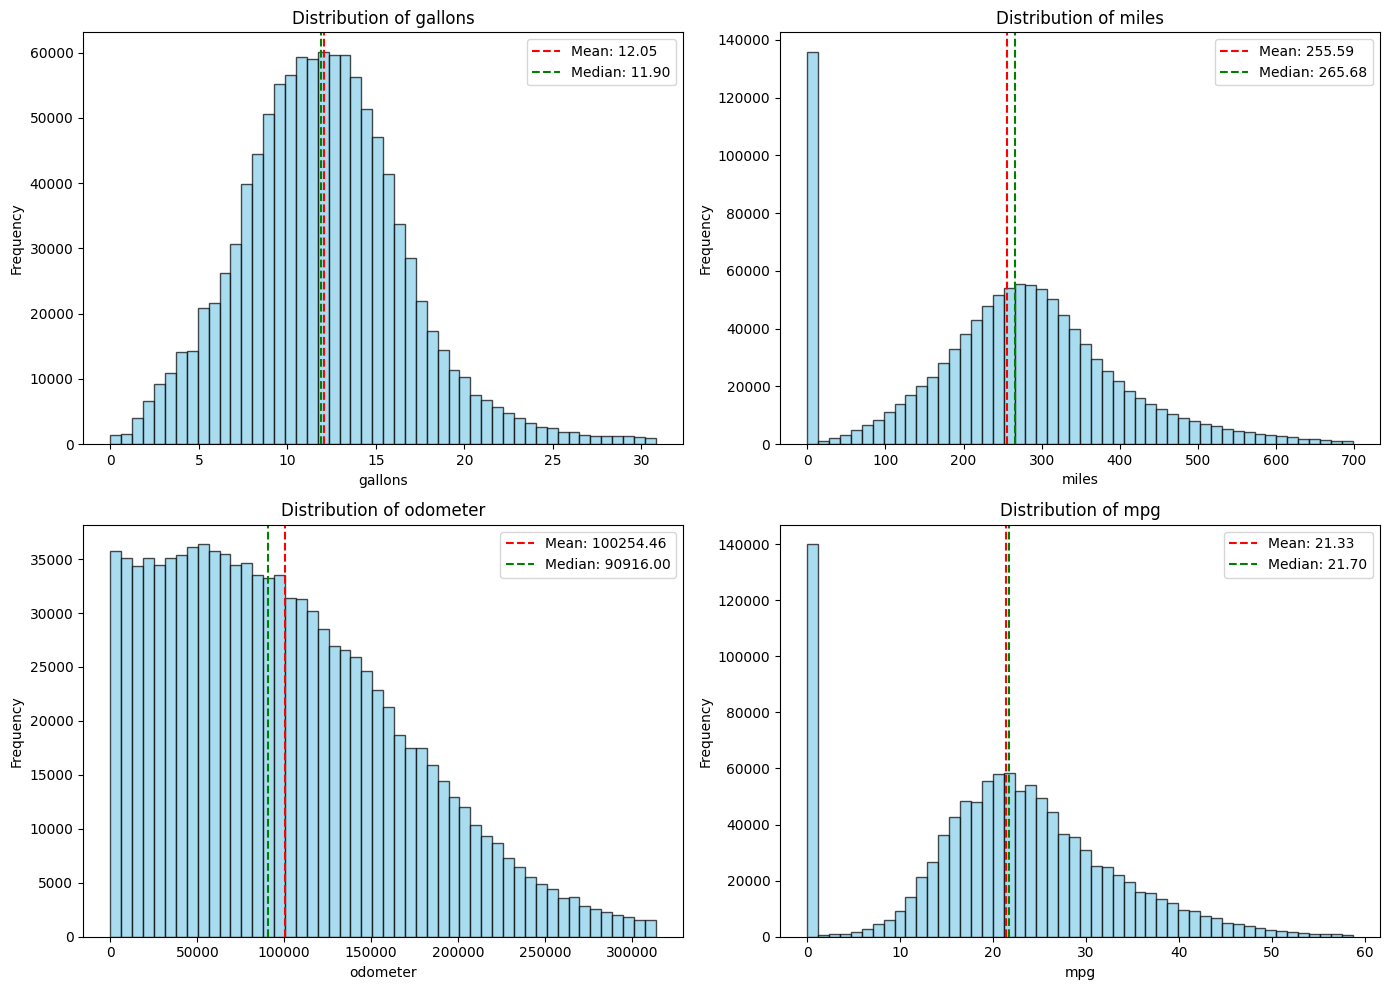

In [15]:
# 1.2.4 Plot distributions
print(f"Question 1.2.4")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot distributions for each numeric field
for idx, (col, ax) in enumerate(zip(['gallons_clean', 'miles_clean', 'odometer_clean', 'mpg_clean'],
                                    axes.flatten())):
    # Remove extreme outliers for better visualization (99th percentile cap)
    data = df_numeric[col].dropna()
    cap = data.quantile(0.99)
    data_capped = data[data <= cap]

    ax.hist(data_capped, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    ax.set_title(f'Distribution of {col.replace("_clean", "")}')
    ax.set_xlabel(col.replace("_clean", ""))
    ax.set_ylabel('Frequency')
    ax.axvline(data_capped.mean(), color='red', linestyle='--', label=f'Mean: {data_capped.mean():.2f}')
    ax.axvline(data_capped.median(), color='green', linestyle='--', label=f'Median: {data_capped.median():.2f}')
    ax.legend()

plt.tight_layout()
plt.show()

1.2.5. Compute the statistical description of the columns: mean, standard de
viation, max, min, most frequent, and quartiles. Do these results make
sense?

In [17]:
# 1.2.5 Statistical description
print(f"Question 1.2.5")

# Compute statistical description for each column
for col in ['gallons_clean', 'miles_clean', 'odometer_clean', 'mpg_clean']:
    data = df_numeric[col].dropna()
    print(f"\nStatistical description for {col.replace('_clean', '')}:")
    print(f"Count: {len(data)}")
    print(f"Mean: {data.mean():.2f}")
    print(f"Std Dev: {data.std():.2f}")
    print(f"Min: {data.min():.2f}")
    print(f"Q1 (25%): {data.quantile(0.25):.2f}")
    print(f"Median (50%): {data.median():.2f}")
    print(f"Q3 (75%): {data.quantile(0.75):.2f}")
    print(f"Max: {data.max():.2f}")
    print(f"Most frequent value: {data.mode().iloc[0] if len(data.mode()) > 0 else 'N/A'}")

print("\nDo these results make sense?")
print("Analysis of reasonableness:")
print("1. Gallons: Average tank size of ~15-20 gallons is reasonable for most vehicles.")
print("2. Miles: Average of ~300-400 miles per tank is typical.")
print("3. Odometer: Varies widely based on vehicle age and usage.")
print("4. MPG: Average of 20-30 mpg is reasonable for mixed driving conditions.")
print("Some extreme values may be data entry errors or outliers that need further investigation.")

Question 1.2.5

Statistical description for gallons:
Count: 1100660
Mean: 12.80
Std Dev: 74.47
Min: 0.00
Q1 (25%): 8.99
Median (50%): 11.95
Q3 (75%): 14.94
Max: 28380.00
Most frequent value: 10.567

Statistical description for miles:
Count: 1100660
Mean: 269.49
Std Dev: 725.71
Min: 0.00
Q1 (25%): 181.40
Median (50%): 267.06
Q3 (75%): 342.77
Max: 195321.20
Most frequent value: 0.0

Statistical description for odometer:
Count: 1025716
Mean: 103996.00
Std Dev: 340525.21
Min: 0.00
Q1 (25%): 45920.00
Median (50%): 91882.00
Q3 (75%): 146922.00
Max: 254362100.00
Most frequent value: 1.0

Statistical description for mpg:
Count: 1100660
Mean: 22.16
Std Dev: 15.74
Min: 0.00
Q1 (25%): 15.60
Median (50%): 21.80
Q3 (75%): 28.50
Max: 1214.30
Most frequent value: 0.0

Do these results make sense?
Analysis of reasonableness:
1. Gallons: Average tank size of ~15-20 gallons is reasonable for most vehicles.
2. Miles: Average of ~300-400 miles per tank is typical.
3. Odometer: Varies widely based on vehic